# YOLO11s baseline: one-stage anchor-free detection

## 1. Research question and hypothesis

Can a pretrained YOLO11s provide a useful anchor-free reference under our existing
stride-five training budget? We compare it with the completed Faster R-CNN and
RetinaNet references in notebooks 03 and 04. This is a model-family comparison,
not a single-factor data ablation. We do not assume better validation AP implies
better Kaggle Public performance.

In [1]:
EXPERIMENT = "yolo_baseline"

import json
import logging
import sys
from pathlib import Path
from io import BytesIO

import plotly.express as px
import plotly.io
import polars as pl
import torch
from decouple import config
from IPython.display import Markdown, display
from IPython.display import Image as NotebookImage
from PIL import Image, ImageDraw

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(name)s: %(message)s",
    datefmt="%Y-%m-%dT%H:%M:%S",
    stream=sys.stdout,
    force=True,
)
ROOT = Path.cwd() if Path("pyproject.toml").is_file() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "src"))

from experiments.protocol import (
    BATCH_ID,
    baseline_directory,
    baseline_protocol_table,
    choose_example_frames,
    class_table,
    epoch_table,
    load_records,
    load_settings,
    loss_table,
    metric_table,
    runtime_table,
    train_experiment,
)
from hm2.detection_data import select_frames
from hm2.visualization import draw_frame

SHOULD_TRAIN = False
persist_checkpoint = None
METADATA = Path(config("HM2_METADATA_DIR", default=str(ROOT / "data/metadata"))).expanduser()
manifest = METADATA / "manifest.json"
previous_root = json.loads(manifest.read_text()).get("dataset_root") if manifest.exists() else None
DATA_ROOT = Path(config("HM2_DATA_DIR", default=previous_root or str(ROOT / "data"))).expanduser()
OUTPUT = Path(
    config(
        "HM2_DATA_EXPERIMENT_OUTPUT",
        default=str(ROOT / "runs/data_experiments" / BATCH_ID / EXPERIMENT),
    )
).expanduser()
BASELINE = Path(config("HM2_BASELINE_RESULTS", default=str(baseline_directory(ROOT, EXPERIMENT))))
SETTINGS = load_settings(ROOT, EXPERIMENT)
BASELINE_SETTINGS = load_settings(ROOT, "photometric_augmentation", is_enabled=False)
plotly.io.renderers.default = "plotly_mimetype"
pl.Config.set_tbl_rows(12)
pl.Config.set_tbl_cols(12)


def show_image(image: Image.Image) -> None:
    image.thumbnail((1000, 450))
    buffer = BytesIO()
    image.convert("RGB").save(buffer, format="JPEG", quality=40, optimize=True)
    display(NotebookImage(data=buffer.getvalue(), format="jpeg"))


{
    "Experiment": EXPERIMENT,
    "Training enabled": SHOULD_TRAIN,
    "Output": str(OUTPUT),
    "Baseline records": str(BASELINE),
    "Exact configuration": SETTINGS,
}

{'Experiment': 'yolo_baseline',
 'Training enabled': False,
 'Output': '/Users/nikitalenyk/Desktop/hm2/runs/data_experiments/controlled_data_stride5_5epochs_seed2026/yolo_baseline',
 'Baseline records': '/Users/nikitalenyk/Desktop/hm2/runs/faster_rcnn/faster_rcnn_stride5_5epochs_seed2026/baseline_stride5',
 'Exact configuration': {'dataset': {'frame_stride': 5,
   'expected_selected_frames': 4868,
   'expected_selected_clips': 56,
   'expected_validation_frames': 2846,
   'should_stage_images': True},
  'model': {'backend': 'ultralytics',
   'model_id': 'yolo11s.pt',
   'pretrained': True,
   'min_size': 640,
   'max_size': 1024,
   'num_classes': 8,
   'score_thresh': 0.05,
   'nms_thresh': 0.5,
   'detections_per_img': 500,
   'is_ignore_aware': True},
  'loss': {'box': 7.5, 'cls': 0.5, 'dfl': 1.5},
  'training': {'seed': 2026,
   'epochs': 5,
   'batch_size': 2,
   'num_workers': 2,
   'learning_rate': 0.0025,
   'warmup_updates': 100,
   'flip_probability': 0.5,
   'checkpoint_seco

## 2. Baseline and experimental configuration

We retain 4,868 stride-five frames, full validation on 2,846 frames from seven separate
clips, seed 2026, batch size 2, five epochs, SGD LR 0.0025, momentum 0.9, weight decay
0.0001, 100-update warmup and the original two LR reductions. New runs start from
COCO-pretrained `yolo11s.pt`, with the foreground head configured for eight classes.

YOLO11s uses native CIoU box loss, BCE classification and distribution focal loss,
with gains 7.5, 0.5 and 1.5. Unlike Faster R-CNN, its input stays in [0, 1] without
ImageNet mean/std normalization. The adapter retains the 640/1024 aspect-ratio resize,
pads on the right/bottom to a multiple of 32 with 114/255 and restores original pixels.
Class IDs 0–7 inside YOLO become 1–8 for the common evaluator.
The exact effective recipe is displayed above from `config/yolo_baseline.toml`.

In [2]:
has_metadata = all(
    (METADATA / f"{name}.parquet").is_file() for name in ("frames", "objects", "ignored_regions")
)
selected = validation = frames = objects = ignored = pl.DataFrame()
if has_metadata:
    frames, objects, ignored = (
        pl.read_parquet(METADATA / f"{name}.parquet")
        for name in ("frames", "objects", "ignored_regions")
    )
    selected = select_frames(frames, "train", 5)
    validation = select_frames(frames, "val")
    display(
        pl.DataFrame(
            {
                "Split": ["Training stride 5", "Official validation"],
                "Frames": [selected.height, validation.height],
                "Clips": [selected["clip"].n_unique(), validation["clip"].n_unique()],
            }
        )
    )
else:
    display(
        Markdown(
            "**Data not restored.** Run `00_data.ipynb` or restore the original parquet metadata. No download is started."
        )
    )

has_images = (
    has_metadata and DATA_ROOT.is_dir() and (DATA_ROOT / selected["relative_path"][0]).is_file()
)

Split,Frames,Clips
str,i64,i64
"""Training stride 5""",4868,56
"""Official validation""",2846,7


## 3. Data and ignored-region diagnostics

We keep the original horizontal flip probability 0.5. We call the native network
and criterion inside the shared loop, not the Ultralytics trainer, so mosaic, mixup,
HSV, random scaling, optimizer auto-selection and gradient accumulation do not run.

Negative candidate points whose centers fall inside ignored regions are excluded
from BCE. Every task-aligned foreground assignment remains valid, even inside an
ignored region. Regression and DFL use the unchanged positive targets. This is an
explicit anchor-free ignore policy, not a claim about Kaggle's exact crowd scorer.

class_name,GT boxes
str,u32
"""car""",101814
"""person""",66353
"""motor""",20712
"""van""",9452
"""tricycle""",8337
"""bicycle""",8129
"""truck""",6137
"""bus""",1945


**Dark sample:** `train/uav0000145_00000_v/0000061`

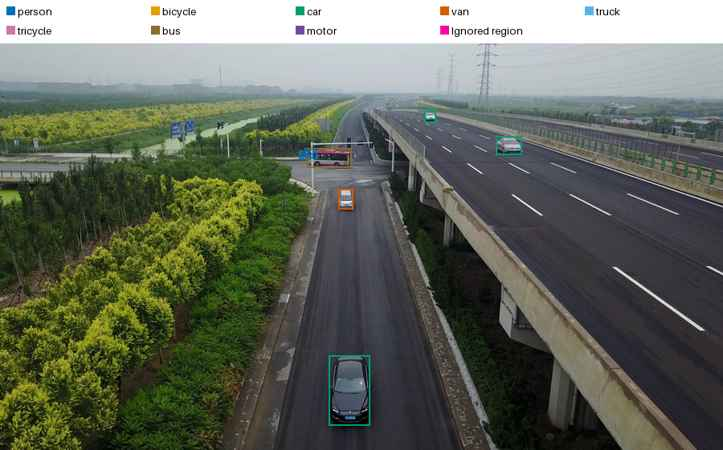

**Crowded:** `train/uav0000150_02310_v/0000321`

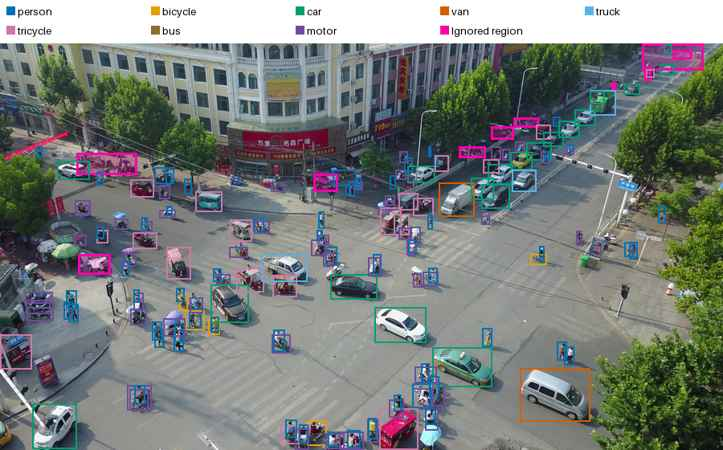

**Small objects:** `train/uav0000124_00944_v/0000001`

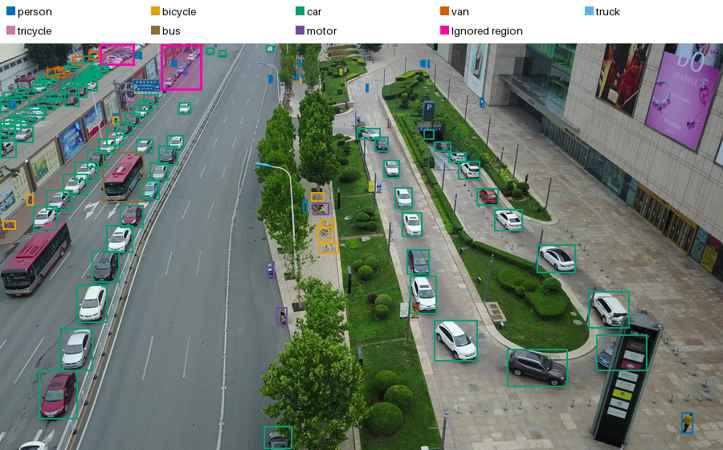

In [3]:
if has_metadata:
    counts = (
        objects.join(selected.select("image_key"), on="image_key", how="semi")
        .group_by("class_name")
        .len(name="GT boxes")
        .sort("GT boxes", descending=True)
    )
    display(counts)
if has_images:
    for record in choose_example_frames(DATA_ROOT, selected, objects):
        display(Markdown(f"**{record['Reason']}:** `{record['image_key']}`"))
        show_image(
            draw_frame(
                DATA_ROOT / record["relative_path"],
                objects.filter(pl.col("image_key") == record["image_key"]),
                ignored.filter(pl.col("image_key") == record["image_key"]),
                max_width=900,
                should_label=False,
            )
        )
else:
    display(Markdown("**Examples unavailable.** Restore original images and parquet metadata."))

## 4. Experiment execution

This five-epoch YOLO11s run is completed. We keep its checkpoint and saved records
on Drive. This notebook loads the measurements with training disabled.
The Kaggle execution notebook now runs the three remaining Faster R-CNN data ablations;
YOLO11s is excluded from that queue.

In [4]:
if SHOULD_TRAIN:
    if persist_checkpoint is None:
        raise RuntimeError(
            "Configure verified Drive persistence through the execution notebook first."
        )
    display(
        train_experiment(
            EXPERIMENT, DATA_ROOT, METADATA, OUTPUT, SETTINGS, on_checkpoint=persist_checkpoint
        )
    )
else:
    display(
        Markdown(
            "**Training disabled.** Use the dedicated execution notebook when GPU execution is authorized."
        )
    )

**Training disabled.** Use the dedicated execution notebook when GPU execution is authorized.

## 5. Training and validation results

We load measured records on every run. Missing results remain Not run, and unfinished
training remains Partial. Final-epoch metrics are the controlled comparison; best-validation
metrics are shown separately. New ablations retain best.pt, while the historical Faster
R-CNN baseline retained only latest.pt. A best metric in its history does not imply its
old checkpoint is still available. Timings exclude setup and checkpoint transfer.

In [5]:
variant = load_records(OUTPUT)
baseline = load_records(BASELINE)
retina = load_records(
    ROOT / "results/retinanet/retinanet_stride5_full_5epochs_seed2026/standard_anchors_stride5"
)
records = {"Faster R-CNN": baseline, "RetinaNet": retina, "YOLO11s": variant}
display(metric_table(records))
display(runtime_table(records))
display(baseline_protocol_table(baseline, BASELINE_SETTINGS))
if variant["config"]:
    display(variant["config"])
if variant["status"] == "Not run":
    display(
        Markdown(
            "**Not run.** No trained-variant validation metrics exist yet. Baseline values do not establish an improvement."
        )
    )
if has_images and baseline["config"].get("dataset_selection_sha256"):
    from hm2.faster_rcnn_experiments import compute_source_identity

    keys = selected["image_key"].to_list()
    actual_identity = compute_source_identity(DATA_ROOT, keys)
    display(
        pl.DataFrame(
            {
                "Exact baseline dataset/selection hash matches": [
                    actual_identity == baseline["config"]["dataset_selection_sha256"]
                ]
            }
        )
    )

Run,Status,Selection,Epoch,mAP,AP50,AP75,AP small,AP medium,AP large,Training min,Validation ms/frame
str,str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""Faster R-CNN""","""Completed""","""Final epoch""",5,0.174703,0.353521,0.152856,0.080675,0.168725,0.334301,75.631758,89.321728
"""Faster R-CNN""","""Completed""","""Best validation epoch""",1,0.192021,0.398392,0.161919,0.089808,0.177219,0.354186,15.262009,92.792669
"""RetinaNet""","""Completed""","""Final epoch""",5,0.152786,0.291178,0.14184,0.053135,0.131627,0.316873,59.605619,124.379205
"""RetinaNet""","""Completed""","""Best validation epoch""",5,0.152786,0.291178,0.14184,0.053135,0.131627,0.316873,59.605619,124.379205
"""YOLO11s""","""Completed""","""Final epoch""",5,0.15499,0.297651,0.144655,0.092178,0.148444,0.284616,23.706654,68.776141
"""YOLO11s""","""Completed""","""Best validation epoch""",5,0.15499,0.297651,0.144655,0.092178,0.148444,0.284616,23.706654,68.776141


Run,Status,Training min,Validation min,Images/s,Peak allocated MiB,Minimum free MiB,GPU
str,str,f64,f64,f64,f64,f64,str
"""Faster R-CNN""","""Completed""",75.631758,34.744474,5.363708,null,null,"""Tesla T4"""
"""RetinaNet""","""Completed""",59.605619,40.955453,6.805846,null,null,"""Tesla T4"""
"""YOLO11s""","""Completed""",23.706654,27.066406,17.111933,1006.375,13132.8125,"""Tesla T4"""


Setting,Expected,Recorded,Matches
str,str,str,bool
"""seed""","""2026""","""2026""",true
"""epochs""","""5""","""5""",true
"""batch_size""","""2""","""2""",true
"""learning_rate""","""0.0025""","""0.0025""",true
"""warmup_updates""","""100""","""100""",true
"""flip_probability""","""0.5""","""0.5""",true
"""frame_stride""","""5""","""5""",true
"""min_size""","""640""","""640""",true
"""max_size""","""1024""","""1024""",true


{'data_experiment': {'name': 'yolo_baseline',
  'kind': 'Anchor-free architecture baseline',
  'ignore_policy': 'Exclude negative points in ignored regions; preserve positives',
  'ultralytics_version': '8.3.235',
  'best_checkpoint': 'Highest full-validation COCO mAP; final epoch is primary'},
 'experiment_id': 'yolo_baseline',
 'seed': 2026,
 'epochs': 5,
 'batch_size': 2,
 'learning_rate': 0.0025,
 'warmup_updates': 100,
 'flip_probability': 0.5,
 'frame_stride': 5,
 'selected_frame_count': 4868,
 'dataset_selection_sha256': '3ba20946c7dcea379abcd156f37dbf6ae12931e94fd94f31d24c7c46d1e3ee74',
 'model': {'backend': 'ultralytics',
  'model_id': 'yolo11s.pt',
  'pretrained': True,
  'min_size': 640,
  'max_size': 1024,
  'num_classes': 8,
  'score_thresh': 0.05,
  'nms_thresh': 0.5,
  'detections_per_img': 500,
  'is_ignore_aware': True},
 'optimizer': {'backend': 'SGD', 'momentum': 0.9, 'weight_decay': 0.0001},
 'loss': {'box_regression': 'ciou',
  'classification': 'binary_cross_entro

Exact baseline dataset/selection hash matches
bool
true


## 6. Measured model references

We report the common canonical COCO bbox evaluator, IoU 0.50:0.95 and maxDets
[1, 10, 100], using original category-specific crowd annotations. The models retain
their native losses and normalization; this is not a one-factor ablation. Historical
RetinaNet inference was capped at 300 detections, while Faster R-CNN and YOLO11s use
500. Faster R-CNN and YOLO11s additionally record maxDets 500. Final epochs and
best-validation epochs remain separate. Timings from different devices or sessions
are not a controlled hardware comparison.

In [6]:
epochs = epoch_table(records)
if not epochs.is_empty():
    for metric in ("mAP", "AP50", "AP75", "AP small", "AP medium", "AP large"):
        display(
            px.line(
                epochs.filter(pl.col("Metric") == metric),
                x="Epoch",
                y="AP",
                color="Run",
                markers=True,
                title=f"Validation {metric}",
            ).update_layout(width=1000, height=420, legend=dict(orientation="h", y=-0.25))
        )
classes = class_table(records)
if not classes.is_empty():
    display(classes.pivot(on="Run", index=["Class", "Epoch"], values="AP"))
    display(
        px.bar(
            classes,
            x="Class",
            y="AP",
            color="Run",
            barmode="group",
            title="Per-class AP at the last completed validation",
        ).update_layout(width=1000, height=450, legend=dict(orientation="h", y=-0.25))
    )
for label, record in records.items():
    curve = loss_table(record)
    if not curve.is_empty():
        display(
            px.line(curve, x="Updates", y="Loss", title=f"{label}: training loss").update_layout(
                width=1000, height=420
            )
        )
        display(
            px.line(
                curve, x="Updates", y="Learning rate", title=f"{label}: learning-rate schedule"
            ).update_layout(width=1000, height=380)
        )

Class,Epoch,Faster R-CNN,RetinaNet,YOLO11s
str,i64,f64,f64,f64
"""person""",5,0.247199,0.203834,0.209177
"""bicycle""",5,0.14803,0.106394,0.121125
"""car""",5,0.356788,0.339475,0.361619
"""van""",5,0.236865,0.164058,0.221142
"""truck""",5,0.139097,0.162982,0.094463
"""tricycle""",5,0.16438,0.140784,0.128774
"""bus""",5,0.014804,0.03764,0.019428
"""motor""",5,0.090464,0.067124,0.084193


## 7. Interpretation and limitations

The final epoch also has the best validation mAP: **0.154990**, with AP50 **0.297651**
and AP small **0.092178**. The accepted `yolo_baseline_stride5.csv` scored **0.14348**
on Kaggle Public, as observed in the submitted-results screenshot on 7 November 2026.
Our Faster R-CNN epoch-five reference scored 0.174703 validation mAP and 0.20369 Public.
YOLO11s underperformed that reference under this five-epoch protocol.

Validation mAP rose from 0.087870 in epoch one to 0.154990 in epoch five.
This suggests checking convergence and the learning-rate recipe before attributing
the result to the architecture. The shared SGD schedule was chosen for a controlled
budget, rather than tuned for YOLO. The native Ultralytics trainer, its augmentation
stack and EMA were not used. These are possible explanations, not established causes.
A native-versus-adapter validation comparison remains an unrun diagnostic.

We verified checkpoint identity, class mapping, original-pixel bounds and all 3,811
submission rows. These checks do not establish the cause of the lower score.
We retain the completed YOLO baseline and continue the three independent Faster R-CNN
ablations without retraining YOLO or selecting their settings from Public feedback.

Ultralytics is pinned to 8.3.235. CPU tests cover native-loss equivalence without ignore
exclusions, preserved positives, unchanged box/DFL losses, gradient flow, coordinates
and checkpoint IO. Original records stay on Drive; restore them through
`HM2_DATA_EXPERIMENT_OUTPUT` when rerunning this analysis.

Sources: [YOLO11](https://docs.ultralytics.com/models/yolo11/) and
[the pinned native loss implementation](https://github.com/ultralytics/ultralytics/blob/v8.3.235/ultralytics/utils/loss.py).